# Grenoble Degree of Separation (DoS): 2017–2022 (bike DoS 1–6) + 2026 (bike DoS 1–6 + car roads)

Same workflow as `notebooks/01_build_lts_networks.ipynb`, but the bicycle categories are the **Degree of Separation**
built from the Geovélo queries in `./sql` (before: OSM `.pbf` → PostGIS; now: **Overpass**, no database needed).

* **Download:** Overpass through `cyclelts.overpass.download_graph` (historical snapshot on 31 Dec for 2017–2022, current OSM for 2026).
  The OSMnx `bike` network is completed with footways/bus guideways where `bicycle=yes|designated|permissive`
  (needed by *Trottoirs cyclables*, *Pistes sur trottoirs*, *Footway designated*…). Steps are removed, as in the LTS study.
* **Classification:** every `WHERE` condition of `./sql/*.sql` is run unchanged on an in-memory SQLite table that mimics
  `planet_osm_line` (one row per OSM way with its raw tags). Query → `tagsmapping.csv` → `tags_mapping_final.csv` → DoS:

  | group | a_High | b_Medium_High | c_Medium | d_Medium_Low | e_Low | f_Null_or_Others |
  |---|---|---|---|---|---|---|
  | **DoS** | **6** (completely separated) | 5 | 4 | 3 | 2 | **1** |

  A way matched by several queries (e.g. *Bandes cyclables* inside a *Zone 30*) takes the **highest** DoS.
  A bike-network way matched by no query (plain shared street, no facility) gets `UNMATCHED_DOS` (= 1, "Null").
* **2026 car roads (DoS 0):** drivable roads whose OSM way is not in the bicycle network (the DoS analogue of LTS 5).
  Flag `mandatory_upgrade_to_dos6=True` when dangerous (speed ≥ 50 km/h, ≥ 4 lanes, primary/secondary) and cycling not prohibited.
* **Simplification (every year):** undirected `nx.Graph` (lowest DoS kept on parallel edges), largest connected component,
  degree-2 nodes removed when both edges have the same DoS, summed length.

By default the Overpass responses already downloaded by the LTS run are reused (`REUSE_CACHE_FROM`), so the DoS and LTS
networks come from **exactly the same OSM snapshots**. Only the small footway query is downloaded new.
Old PBF/PostGIS version: `Grenoble_study.ipynb`.

## 1. Settings

In [1]:
import os, sys
from pathlib import Path
# GDAL/PROJ data of this conda env (missing when the kernel starts without `conda activate`)
for var, sub in (("GDAL_DATA", "gdal"), ("PROJ_DATA", "proj")):
    folder = Path(sys.prefix) / "Library" / "share" / sub
    if folder.exists():
        os.environ.setdefault(var, str(folder))
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cyclelts").is_dir())
sys.path.insert(0, str(ROOT))   # the cyclelts package (repository root)

import pickle
import geojson
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import shape
from IPython.display import display

from cyclelts import config
from cyclelts.overpass import OVERPASS_ENDPOINTS
from cyclelts.lts import configure_osmnx, normalize_polygon
from cyclelts.network import normalize_snapshot_date
import dos_network as dos

# ---- CHANGE THESE ---------------------------------------------------------
CITY = "Grenoble"
CITY_INSEE = None

RUN_NAME = "dos_2026-10-31"   # new name = fresh build; same name = resume
REBUILD = False               # True = ignore pickles inside THIS run folder
# Reuse the Overpass responses of the LTS run (same OSM snapshots). None = download everything again.
REUSE_CACHE_FROM = config.run_dir(CITY) / "osm_http_cache"
UNMATCHED_DOS = 1             # DoS of bike-network ways with no Geovelo facility (plain shared streets)
# ---------------------------------------------------------------------------

HISTORICAL_YEARS = list(range(2017, 2023))
CURRENT_YEAR = 2026
TIMEOUT = 600
ENDPOINTS = OVERPASS_ENDPOINTS

poly = config.load_city_polygon(CITY, CITY_INSEE)   # data/city_polygons.geojson

SLUG = CITY.lower().replace(" ", "_").replace("'", "")
RUN = Path("dos_output") / SLUG / RUN_NAME
CACHE = RUN / "osm_http_cache"
RUN.mkdir(parents=True, exist_ok=True)
if REUSE_CACHE_FROM is not None:
    dos.seed_cache(REUSE_CACHE_FROM, CACHE)
polygon = normalize_polygon(poly)
configure_osmnx()

rules = dos.load_rules()   # ./sql + tagsmapping.csv + tags_mapping_final.csv
print("City:", CITY, "| Polygon:", poly.geom_type, "| Bounds:", poly.bounds)
print("Output:", RUN.resolve())
display(rules.groupby(["dos", "group", "category"]).size().rename("n_sql_files").to_frame())

Communes file: \communes-20220101.json


[cache] copied 0 cached Overpass responses from ..\lts_output\grenoble\fresh_2026-10-21\osm_http_cache
[rules] skipped (not in tagsmapping.csv): All.sql, cars_network.sql
City: Grenoble | Polygon: Polygon | Bounds: (5.677606, 45.154144, 5.753118, 45.214076)
Output: \DoS_Category\dos_output\grenoble\dos_2026-10-31


n_sql_files
dos group            category                                           
1   f_Null_or_Others Escalier                                          3
                     Limite_a_30                                       2
                     Pedestrian                                        2
                     Zone_30                                           2
                     Zone_rencontre                                    2
2   e_Low            Cheminements_Cyclables                            3
                     Double_sens_cyclables_sans_bande                  1
3   d_Medium_Low     Accotements Cyclables                             3
                     Bandes_cyclables                                  5
                     Chaucidou                                         1
                     Double_sens_cyclables_en_bande                    2
4   c_Medium         Velorue                                           2
                     Voies_bus                                         3
5   b_Medium_High    Autres_chemins_pitons_autoris_aux_vlos            2
                     Footway_path_designated                           2
                     Footway_permissive                                2
                     Pistes_sur_trottoirs                              4
                     Routes_services_chemins_agricoles                 2
                     Trottoirs_cyclables                               4
                     Voies_vertes                                      2
6   a_High           Double_sens_cyclables_en_piste                    2
                     Pistes_cyclables                                  5

## 2. Build functions

In [2]:
def save(obj, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("wb") as f:
        pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)

def load(path):
    with path.open("rb") as f:   # only open your own pickle files
        return pickle.load(f)

def snapshot(year):
    return None if year == CURRENT_YEAR else normalize_snapshot_date(str(year))

def cache_for(year):
    date = snapshot(year)
    return CACHE / (date[:10] if date else "current")

def get_bike(year):
    path = RUN / str(year) / f"{SLUG}_bike_dos_{year}_prepared.pkl"
    if path.exists() and not REBUILD:
        return load(path)
    bike = dos.build_bike_dos(polygon, rules, date=snapshot(year), cache_folder=cache_for(year),
                              endpoints=ENDPOINTS, server_timeout=TIMEOUT, unmatched_dos=UNMATCHED_DOS)
    bike.graph["year"] = year
    save(bike, path)
    return bike

def get_cars(year):
    path = RUN / str(year) / f"{SLUG}_car_{year}_raw.pkl"
    if path.exists() and not REBUILD:
        return load(path)
    cars, _ = dos.download_with_tags(polygon, "drive", date=snapshot(year), cache_folder=cache_for(year),
                                     endpoints=ENDPOINTS, server_timeout=TIMEOUT)
    save(cars, path)
    return cars

def build_year(year):
    out = RUN / str(year) / f"{SLUG}_dos_{year}_SIMPLE.pkl"
    if out.exists() and not REBUILD:
        print(f"[{year}] loaded {out}")
        return load(out)
    bike = get_bike(year)
    print(f"[{year}] {bike.graph['n_ways_matched']:,} of {bike.graph['n_ways']:,} OSM ways matched a Geovelo query")
    if year == CURRENT_YEAR:
        source = dos.add_car_layer(bike, get_cars(year))
        save(source, RUN / str(year) / f"{SLUG}_dos_cars_{year}_pre_simplification.pkl")
    else:
        source = bike
    H = dos.simplify_dos_graph(source)
    H.graph.update(year=year, city=CITY, snapshot=snapshot(year) or "current OSM")
    check = dos.check_graph(H)
    assert check["connected"] and check["remaining_contractible_degree2_nodes"] == 0
    levels = set(check["dos_counts"])
    assert levels <= ({0, 1, 2, 3, 4, 5, 6} if year == CURRENT_YEAR else {1, 2, 3, 4, 5, 6})
    save(H, out)
    print(f"[{year}] saved {out}")
    return H

## 3. Build all seven networks
Each year is saved as soon as it finishes. If a year fails (busy Overpass server), rerun this cell: finished years load from disk.

In [3]:
graphs, failed = {}, {}
for year in HISTORICAL_YEARS + [CURRENT_YEAR]:
    try:
        graphs[year] = build_year(year)
    except Exception as exc:
        failed[year] = repr(exc)
        print(f"[{year}] FAILED: {exc}")
print("Done:", sorted(graphs), "| Failed:", failed)

[2017] loaded dos_output\grenoble\dos_2026-10-31\2017\grenoble_dos_2017_SIMPLE.pkl
[2018] loaded dos_output\grenoble\dos_2026-10-31\2018\grenoble_dos_2018_SIMPLE.pkl


[2019] loaded dos_output\grenoble\dos_2026-10-31\2019\grenoble_dos_2019_SIMPLE.pkl
[2020] loaded dos_output\grenoble\dos_2026-10-31\2020\grenoble_dos_2020_SIMPLE.pkl


[2021] loaded dos_output\grenoble\dos_2026-10-31\2021\grenoble_dos_2021_SIMPLE.pkl
[2022] loaded dos_output\grenoble\dos_2026-10-31\2022\grenoble_dos_2022_SIMPLE.pkl


[2026] loaded dos_output\grenoble\dos_2026-10-31\2026\grenoble_dos_2026_SIMPLE.pkl


Done: [2017, 2018, 2019, 2020, 2021, 2022, 2026] | Failed: {}


## 4. Network length per DoS level (simplified graphs)
`cycling_km` = DoS 1–6. Car roads (DoS 0) are only in 2026 and are never counted as cycling.

In [4]:
if failed:
    raise RuntimeError(f"Rerun section 3 first; missing years: {sorted(failed)}")
summary = dos.length_by_dos(graphs)
display(summary.round(2))
summary.to_csv(RUN / f"{SLUG}_dos_2017_2022_2026_lengths.csv", index=False)

# km per Geovelo category, first and last year (before simplification, each OSM way segment once)
by_cat = {y: dos.length_by_category(load(RUN / str(y) / f"{SLUG}_bike_dos_{y}_prepared.pkl"))
          for y in (HISTORICAL_YEARS[0], CURRENT_YEAR)}
cat_table = (by_cat[HISTORICAL_YEARS[0]].merge(by_cat[CURRENT_YEAR], on=["DoS", "category"], how="outer",
             suffixes=(f"_{HISTORICAL_YEARS[0]}", f"_{CURRENT_YEAR}")).fillna(0).sort_values(["DoS", f"km_{CURRENT_YEAR}"], ascending=False))
display(cat_table.round(2).reset_index(drop=True))
cat_table.to_csv(RUN / f"{SLUG}_dos_km_per_category.csv", index=False)

,year,DoS6_km,DoS5_km,DoS4_km,DoS3_km,DoS2_km,DoS1_km,cycling_km,car_road_km,car_mandatory_km
0,2017,19.27,55.75,13.28,41.59,34.16,245.84,409.89,0.00,0.0
1,2018,20.35,54.94,12.97,42.61,34.36,248.25,413.48,0.00,0.0
2,2019,21.97,58.28,13.08,39.90,35.68,255.93,424.85,0.00,0.0
3,2020,29.98,52.76,12.69,41.62,35.66,252.56,425.27,0.00,0.0
4,2021,29.66,52.75,10.40,43.60,36.10,260.31,432.82,0.00,0.0
5,2022,30.73,55.64,11.75,42.12,37.16,265.82,443.23,0.00,0.0
6,2026,34.67,41.38,10.37,38.69,48.19,270.93,444.24,24.27,0.0


,DoS,category,km_2017,km_2026
0,6,Pistes_cyclables,19.74,34.96
1,6,Double_sens_cyclables_en_piste,0.08,0.00
2,5,Voies_vertes,27.86,16.80
3,5,Autres_chemins_pitons_autoris_aux_vlos,22.20,13.13
4,5,Footway_permissive,2.68,4.47
5,5,Pistes_sur_trottoirs,0.00,2.26
6,5,Trottoirs_cyclables,1.91,1.97
7,5,Routes_services_chemins_agricoles,0.68,1.60
8,5,Footway_path_designated,0.54,1.54
9,4,Voies_bus,13.55,10.20


## 5. DoS maps (clipped to the city polygon)
Colours: DoS 6 `#66CD00`, 5 `#FFFF00`, 4 `#EE5C42`, 3 `#FF0000`, 2 `#CD0000`, 1 `#000000`. 2026 also shows car roads (grey) and car roads that must be upgraded to DoS 6 (purple).

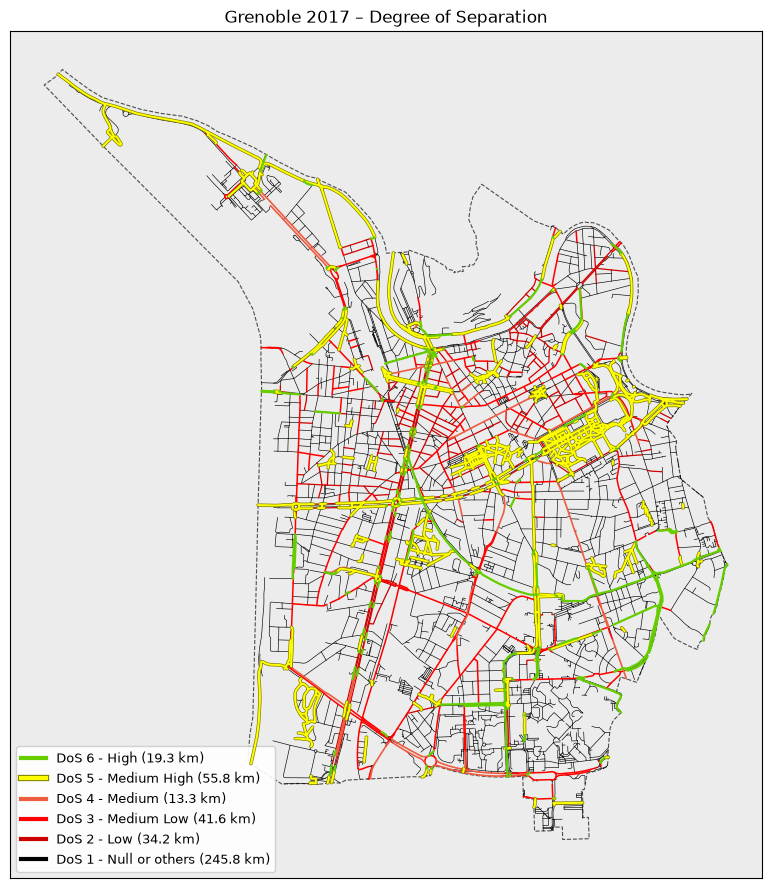

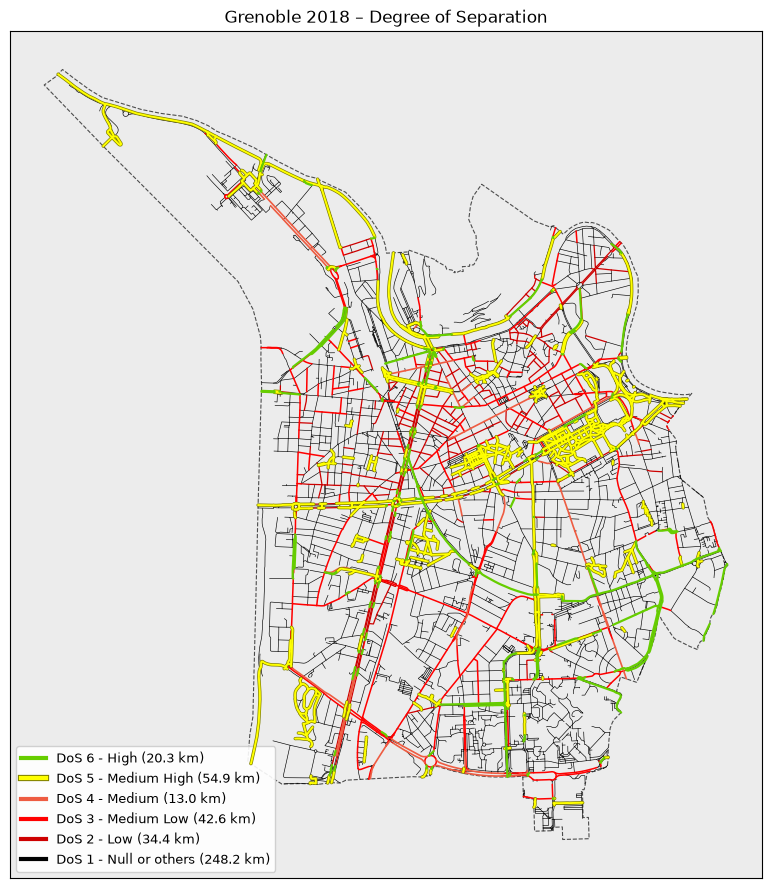

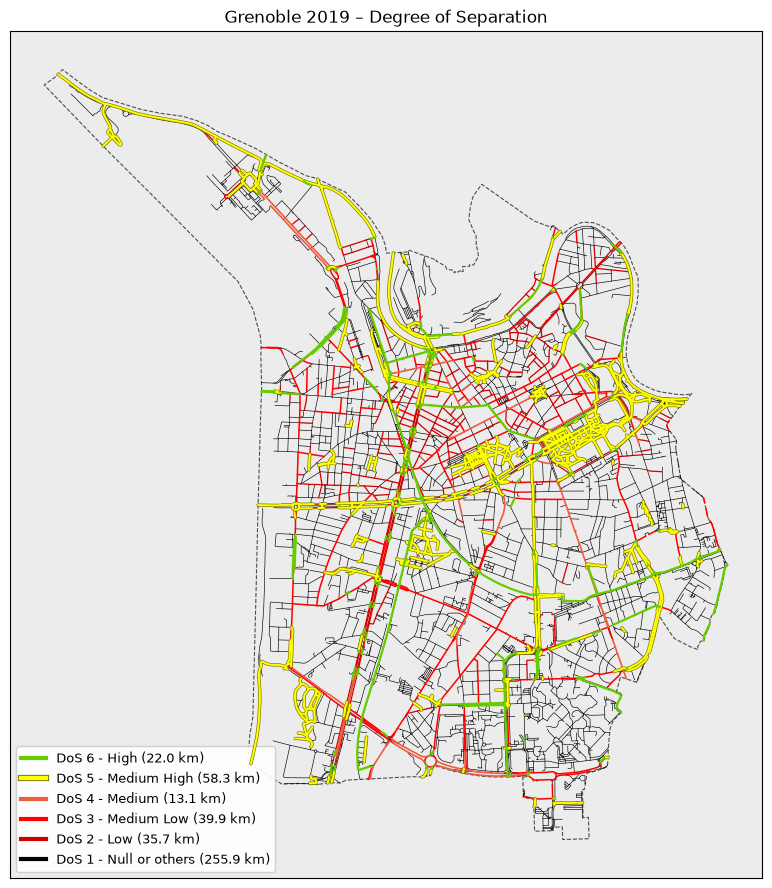

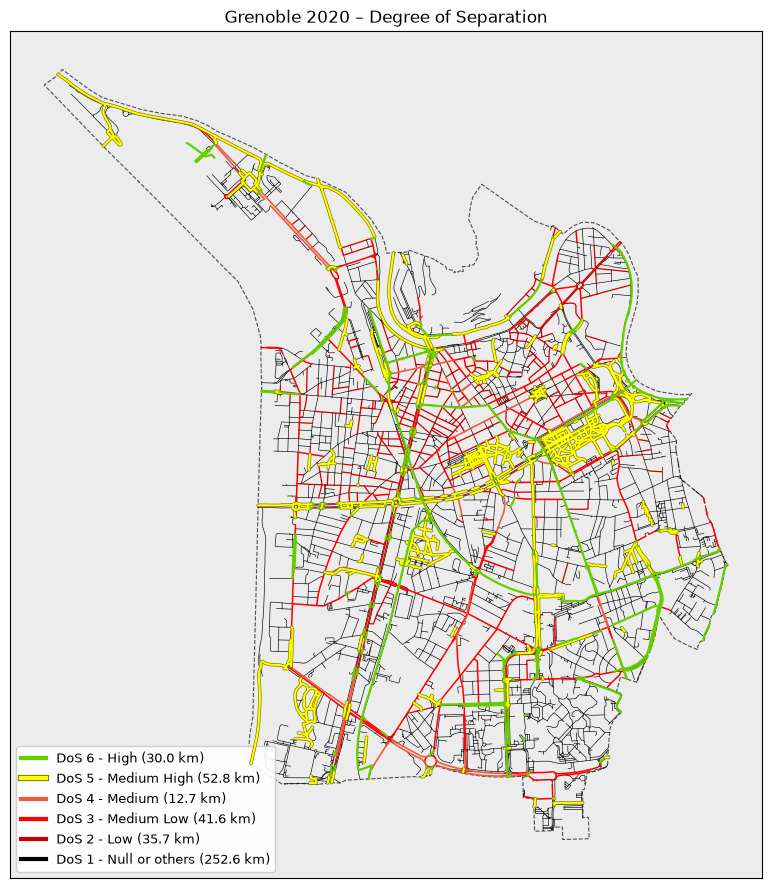

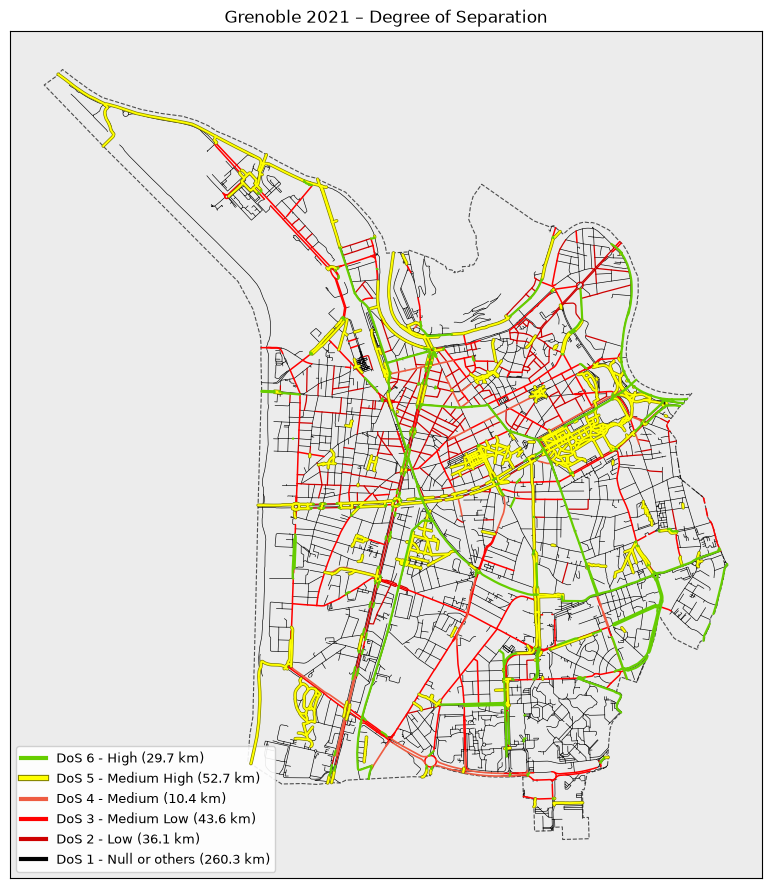

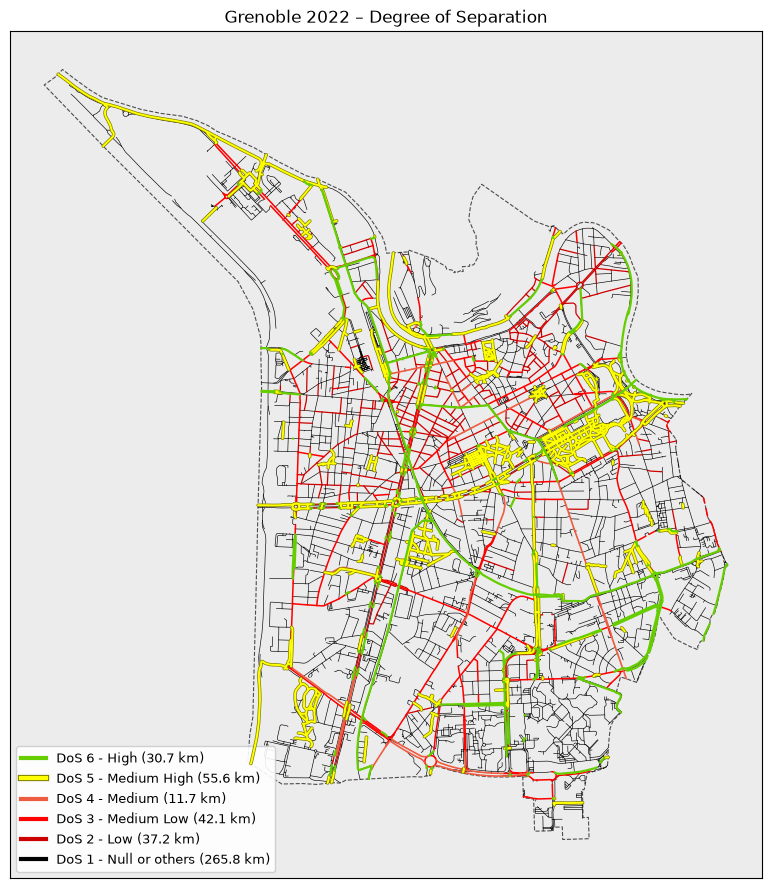

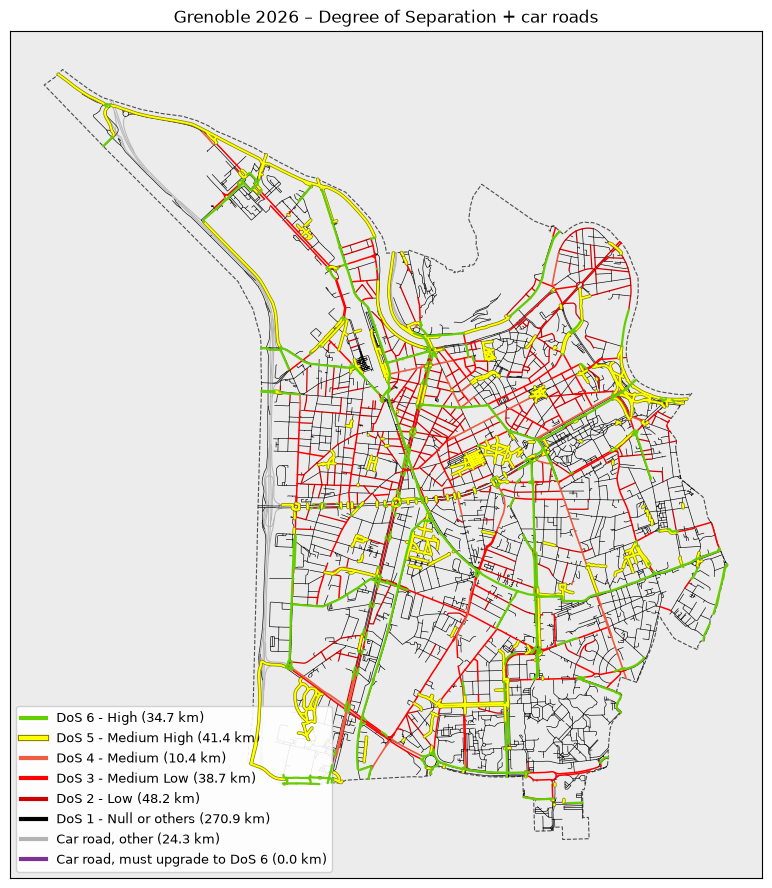

In [5]:
%matplotlib inline
for year, H in sorted(graphs.items()):
    fig, ax = plt.subplots(figsize=(11, 11))
    title = f"{CITY} {year} – Degree of Separation" + (" + car roads" if year == CURRENT_YEAR else "")
    dos.plot_dos(H, title, boundary=poly, ax=ax)
    fig.savefig(RUN / f"{SLUG}_dos_{year}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 6. All years side by side (bike network only)

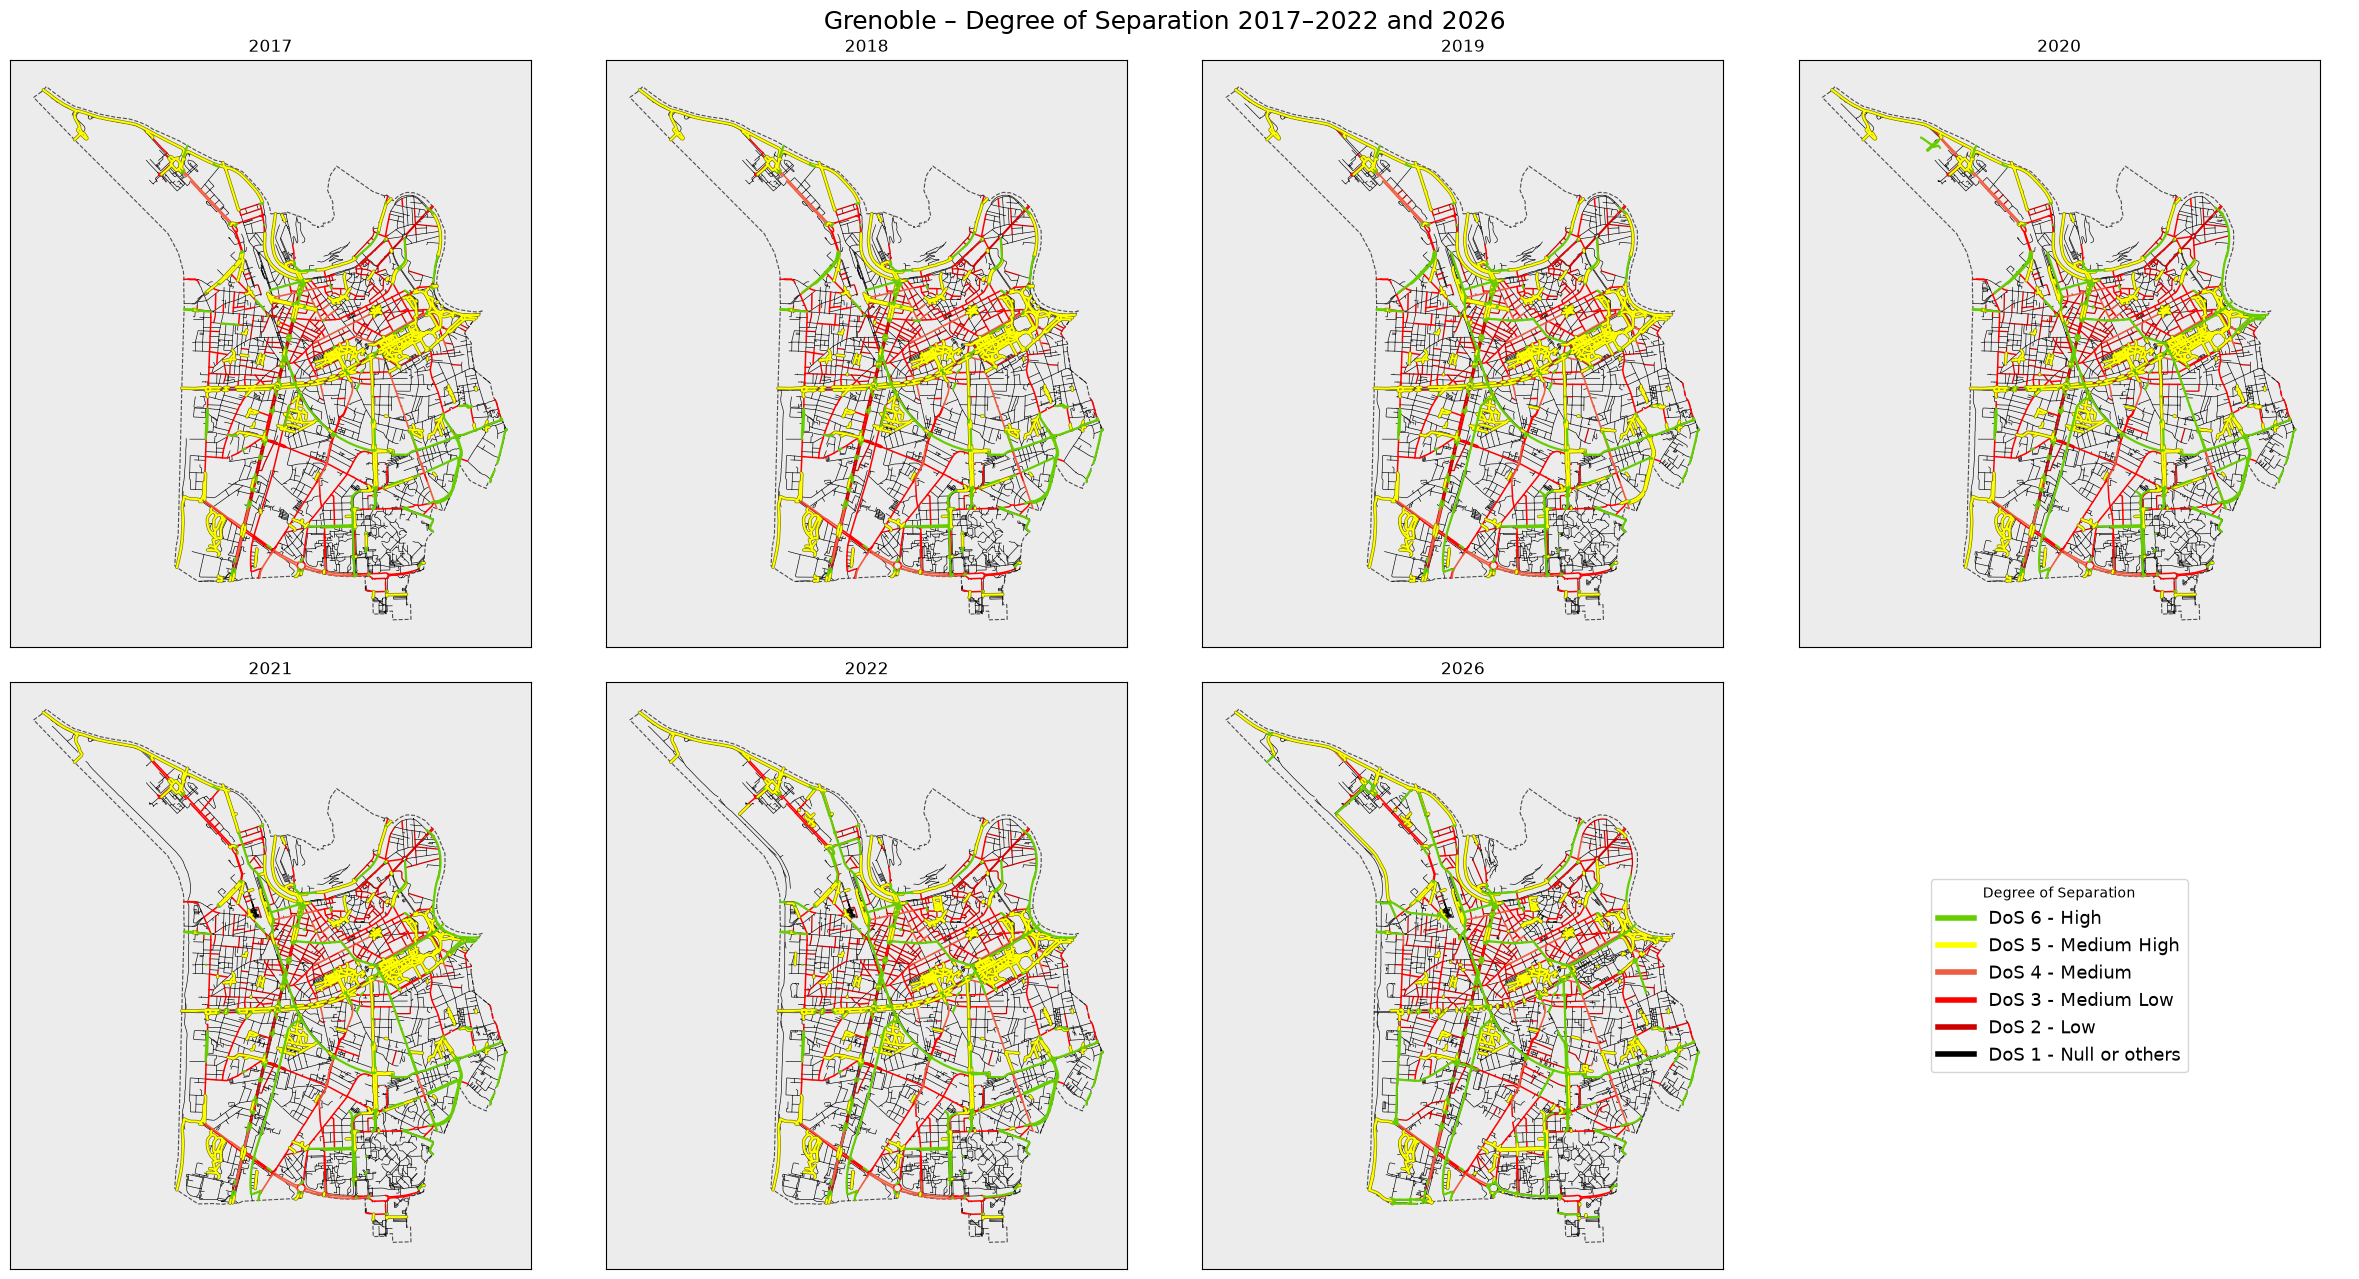

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(24, 13))
for ax, (year, H) in zip(axes.flat, sorted(graphs.items())):
    dos.plot_dos(H, str(year), boundary=poly, ax=ax, show_cars=False)
    ax.get_legend().remove()
axes.flat[-1].axis("off")
handles = [plt.Line2D([], [], color=dos.colors[l], lw=4, label=dos.DOS_LABELS[l]) for l in range(6, 0, -1)]
axes.flat[-1].legend(handles=handles, loc="center", fontsize=13, title="Degree of Separation")
fig.suptitle(f"{CITY} – Degree of Separation 2017–2022 and 2026", fontsize=18)
fig.tight_layout()
fig.savefig(RUN / f"{SLUG}_dos_all_years.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Interactive map (zoom, pan, switch DoS levels on/off)
Change `MAP_YEAR` to see another year. The map is also saved as HTML in the run folder (open it in any browser).

In [7]:
MAP_YEAR = CURRENT_YEAR
m = dos.folium_dos(graphs[MAP_YEAR], poly, title=f"{CITY} {MAP_YEAR} – Degree of Separation")
m.save(str(RUN / f"{SLUG}_dos_{MAP_YEAR}_interactive.html"))
m

## 8. Where everything is saved

In [8]:
for p in sorted(RUN.rglob("*")):
    if p.is_file() and "osm_http_cache" not in p.parts:
        print(f"{p.stat().st_size/1e6:8.2f} MB  {p.resolve()}")

    6.55 MB  \DoS_Category\dos_output\grenoble\dos_2026-10-31\2017\grenoble_bike_dos_2017_prepared.pkl
    2.08 MB  \DoS_Category\dos_output\grenoble\dos_2026-10-31\2017\grenoble_dos_2017_SIMPLE.pkl
    6.74 MB  \DoS_Category\dos_output\grenoble\dos_2026-10-31\2018\grenoble_bike_dos_2018_prepared.pkl
    2.13 MB  \DoS_Category\dos_output\grenoble\dos_2026-10-31\2018\grenoble_dos_2018_SIMPLE.pkl
    7.24 MB  \DoS_Category\dos_output\grenoble\dos_2026-10-31\2019\grenoble_bike_dos_2019_prepared.pkl
    2.23 MB  \DoS_Category\dos_output\grenoble\dos_2026-10-31\2019\grenoble_dos_2019_SIMPLE.pkl
    7.44 MB  \DoS_Category\dos_output\grenoble\dos_2026-10-31\2020\grenoble_bike_dos_2020_prepared.pkl
    2.27 MB  \DoS_Category\dos_output\grenoble\dos_2026-10-31\2020\grenoble_dos_2020_SIMPLE.pkl
    7.97 MB  \DoS_Category\dos_output\grenoble\dos_2026-10-31\2021\grenoble_bike_dos_2021_prepared.pkl
    2.40 MB  \DoS_Category\dos_output\grenoble\dos_2026-10-31\2021\grenoble_dos_2021_SIMPLE.pkl
    8